In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns



# Load dataset
URL = "https://cf-courses-data.s3.us.cloud-object-storage.appdomain.cloud/IBM-DS0321EN-SkillsNetwork/datasets/dataset_part_2.csv"
df = pd.read_csv(URL)

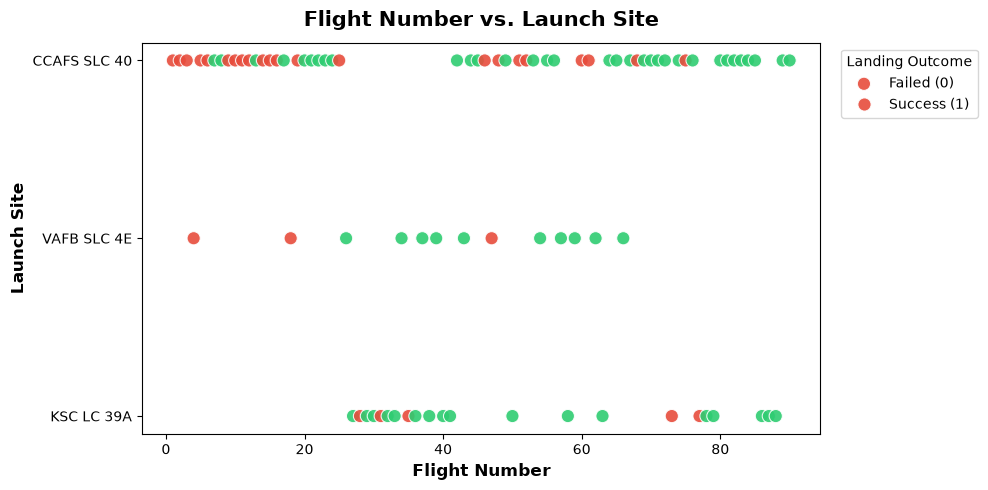

In [3]:
# Slide 18: Flight Number vs. Launch Site
plt.figure(figsize=(10, 5))
sns.scatterplot(
    data=df, 
    x="FlightNumber", 
    y="LaunchSite", 
    hue="Class", 
    palette={0: "#E74C3C", 1: "#2ECC71"}, 
    s=90, 
    alpha=0.9
)
plt.title("Flight Number vs. Launch Site", fontsize=15, fontweight="bold", pad=12)
plt.xlabel("Flight Number", fontsize=12, fontweight="bold")
plt.ylabel("Launch Site", fontsize=12, fontweight="bold")
plt.legend(title="Landing Outcome", labels=["Failed (0)", "Success (1)"], bbox_to_anchor=(1.02, 1), loc='upper left')
plt.tight_layout()
plt.show()

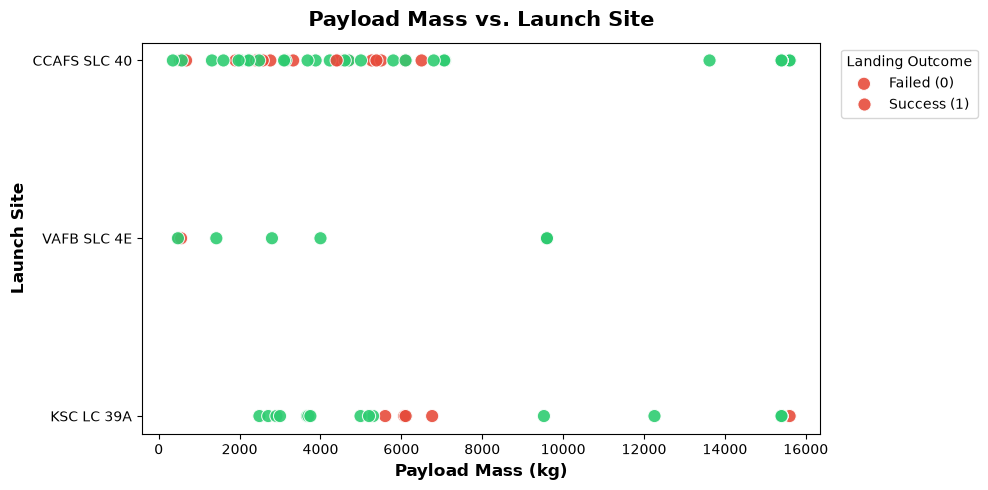

In [4]:
# Slide 19: Payload Mass vs. Launch Site
plt.figure(figsize=(10, 5))
sns.scatterplot(
    data=df, 
    x="PayloadMass", 
    y="LaunchSite", 
    hue="Class", 
    palette={0: "#E74C3C", 1: "#2ECC71"}, 
    s=90, 
    alpha=0.9
)
plt.title("Payload Mass vs. Launch Site", fontsize=15, fontweight="bold", pad=12)
plt.xlabel("Payload Mass (kg)", fontsize=12, fontweight="bold")
plt.ylabel("Launch Site", fontsize=12, fontweight="bold")
plt.legend(title="Landing Outcome", labels=["Failed (0)", "Success (1)"], bbox_to_anchor=(1.02, 1), loc='upper left')
plt.tight_layout()
plt.show()

C:\Users\santo\AppData\Local\Temp\ipykernel_21840\1353210588.py:5: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  barplot = sns.barplot(


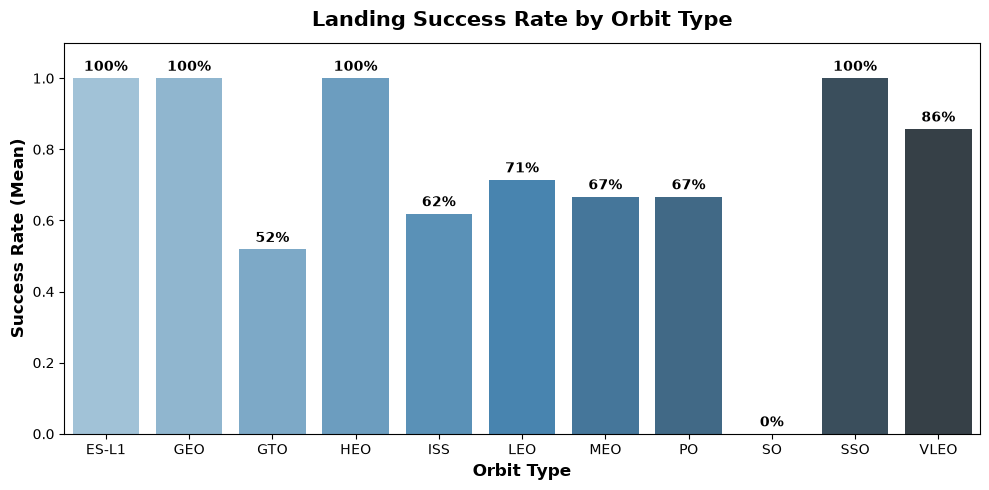

In [5]:
# Slide 20: Success Rate vs. Orbit Type
orbit_success = df.groupby("Orbit")["Class"].mean().reset_index()

plt.figure(figsize=(10, 5))
barplot = sns.barplot(
    data=orbit_success, 
    x="Orbit", 
    y="Class", 
    palette="Blues_d"
)
plt.title("Landing Success Rate by Orbit Type", fontsize=15, fontweight="bold", pad=12)
plt.xlabel("Orbit Type", fontsize=12, fontweight="bold")
plt.ylabel("Success Rate (Mean)", fontsize=12, fontweight="bold")
plt.ylim(0, 1.1)

# Annotate percentages on top of each bar
for p in barplot.patches:
    barplot.annotate(
        f"{p.get_height()*100:.0f}%", 
        (p.get_x() + p.get_width() / 2., p.get_height()), 
        ha='center', va='bottom', fontsize=10, fontweight="bold", xytext=(0, 3), 
        textcoords='offset points'
    )

plt.tight_layout()
plt.show()

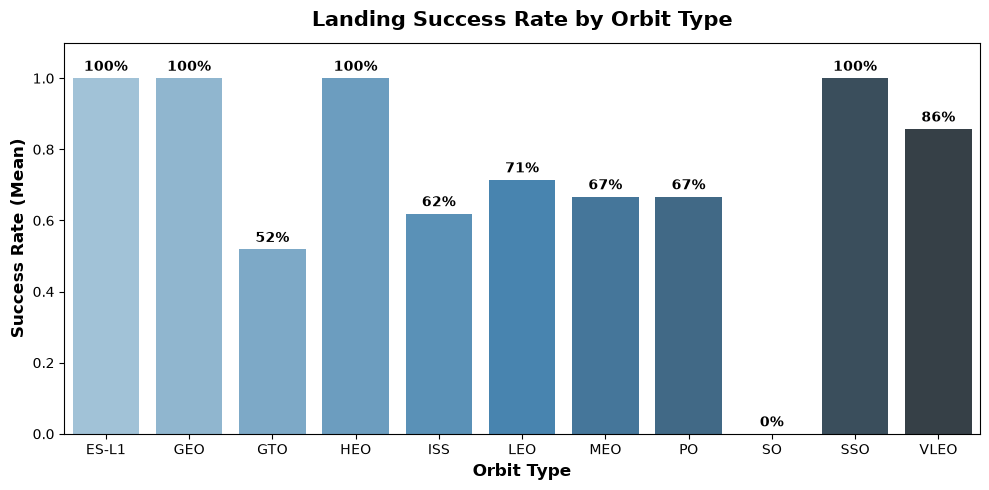

In [6]:
    # Slide 20: Success Rate vs. Orbit Type
orbit_success = df.groupby("Orbit")["Class"].mean().reset_index()

plt.figure(figsize=(10, 5))
barplot = sns.barplot(
    data=orbit_success, 
    x="Orbit", 
    y="Class", 
    hue="Orbit",
    palette="Blues_d",
    legend=False
)
plt.title("Landing Success Rate by Orbit Type", fontsize=15, fontweight="bold", pad=12)
plt.xlabel("Orbit Type", fontsize=12, fontweight="bold")
plt.ylabel("Success Rate (Mean)", fontsize=12, fontweight="bold")
plt.ylim(0, 1.1)

# Annotate percentages on top of each bar
for p in barplot.patches:
    barplot.annotate(
        f"{p.get_height()*100:.0f}%", 
        (p.get_x() + p.get_width() / 2., p.get_height()), 
        ha='center', va='bottom', fontsize=10, fontweight="bold", xytext=(0, 3), 
        textcoords='offset points'
    )

plt.tight_layout()
plt.show()

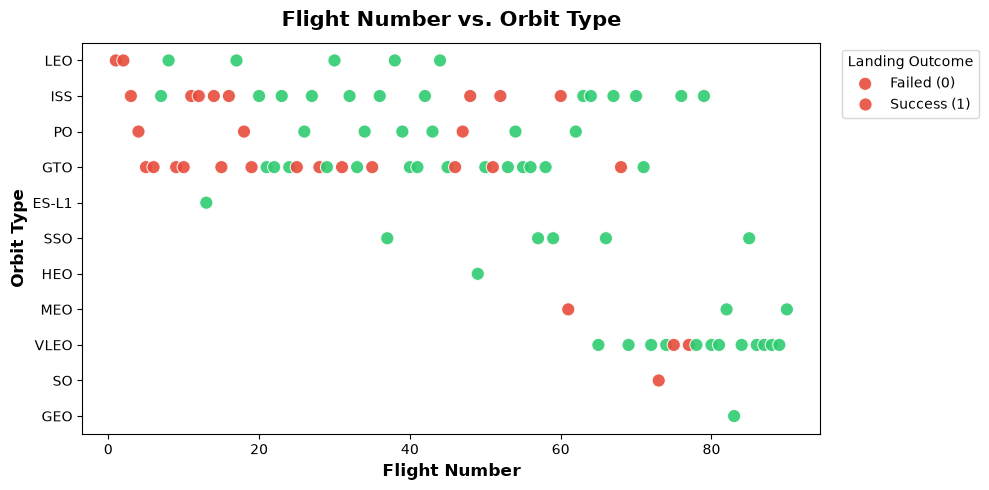

In [7]:
# Slide 21: Flight Number vs. Orbit Type
plt.figure(figsize=(10, 5))
sns.scatterplot(
    data=df, 
    x="FlightNumber", 
    y="Orbit", 
    hue="Class", 
    palette={0: "#E74C3C", 1: "#2ECC71"}, 
    s=90, 
    alpha=0.9
)
plt.title("Flight Number vs. Orbit Type", fontsize=15, fontweight="bold", pad=12)
plt.xlabel("Flight Number", fontsize=12, fontweight="bold")
plt.ylabel("Orbit Type", fontsize=12, fontweight="bold")
plt.legend(title="Landing Outcome", labels=["Failed (0)", "Success (1)"], bbox_to_anchor=(1.02, 1), loc='upper left')
plt.tight_layout()
plt.show()

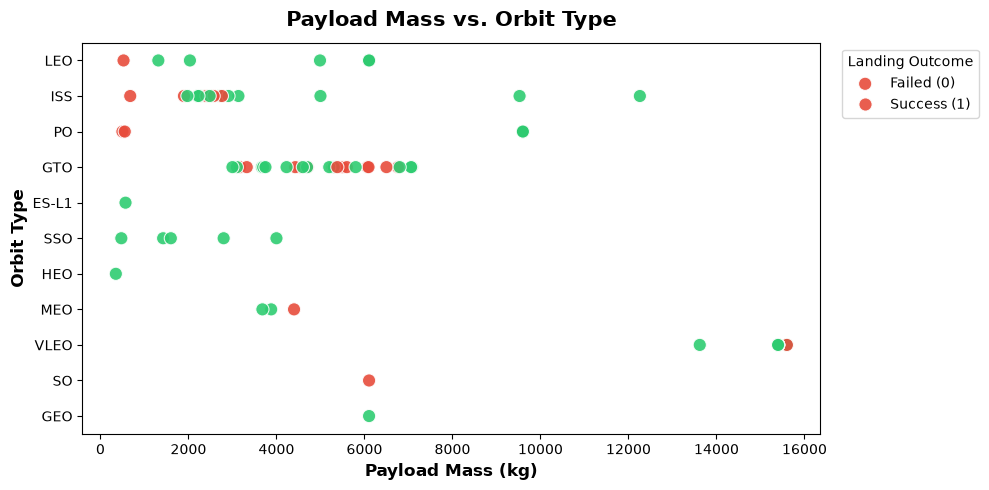

In [8]:
# Slide 22: Payload Mass vs. Orbit Type
plt.figure(figsize=(10, 5))
sns.scatterplot(
    data=df, 
    x="PayloadMass", 
    y="Orbit", 
    hue="Class", 
    palette={0: "#E74C3C", 1: "#2ECC71"}, 
    s=90, 
    alpha=0.9
)
plt.title("Payload Mass vs. Orbit Type", fontsize=15, fontweight="bold", pad=12)
plt.xlabel("Payload Mass (kg)", fontsize=12, fontweight="bold")
plt.ylabel("Orbit Type", fontsize=12, fontweight="bold")
plt.legend(title="Landing Outcome", labels=["Failed (0)", "Success (1)"], bbox_to_anchor=(1.02, 1), loc='upper left')
plt.tight_layout()
plt.show()

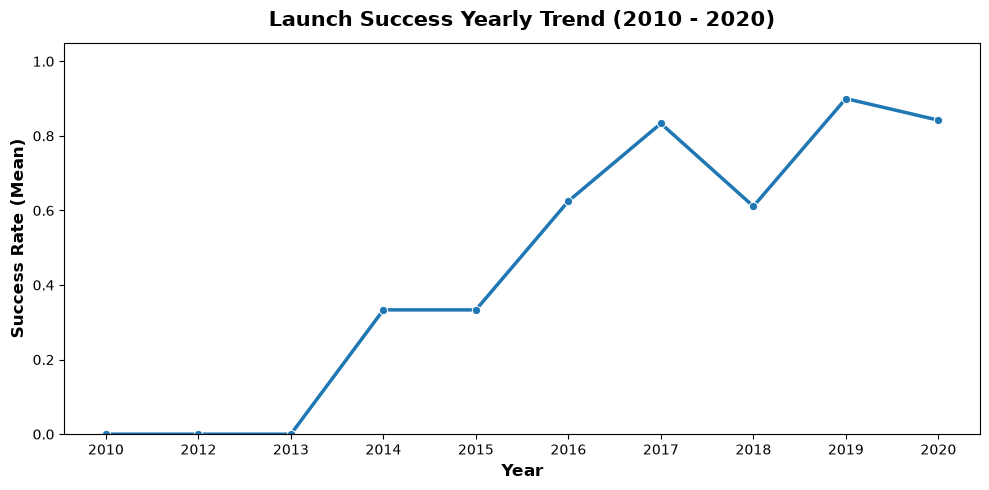

In [9]:
# Slide 23: Launch Success Yearly Trend
# Extract year helper
year = [i.split("-")[0] for i in df["Date"]]
df_year = df.copy()
df_year["Year"] = year
yearly_success = df_year.groupby("Year")["Class"].mean().reset_index()

plt.figure(figsize=(10, 5))
sns.lineplot(
    data=yearly_success, 
    x="Year", 
    y="Class", 
    marker="o", 
    linewidth=2.5, 
    color="#1F77B4"
)
plt.title("Launch Success Yearly Trend (2010 - 2020)", fontsize=15, fontweight="bold", pad=12)
plt.xlabel("Year", fontsize=12, fontweight="bold")
plt.ylabel("Success Rate (Mean)", fontsize=12, fontweight="bold")
plt.ylim(0, 1.05)
plt.tight_layout()
plt.show()

In [12]:
import sqlite3
import pandas as pd

# 1. Download the SpaceX CSV data used for the SQL lab
csv_url = "https://cf-courses-data.s3.us.cloud-object-storage.appdomain.cloud/IBM-DS0321EN-SkillsNetwork/datasets/Spacex.csv"
df_sql = pd.read_csv(csv_url)

# Clean up column names (strip whitespace and standardise)
df_sql.columns = df_sql.columns.str.strip().str.replace(" ", "_").str.replace("-", "_")

# 2. Create in-memory SQLite database connection
conn = sqlite3.connect(":memory:")
df_sql.to_sql("SPACEXTBL", conn, if_exists="replace", index=False)

# Helper function to run and display queries as neat tables
def run_query(query):
    return pd.read_sql_query(query, conn)

HTTPError: HTTP Error 404: Not Found

In [13]:
query_24 = "SELECT DISTINCT Launch_Site FROM SPACEXTBL;"
run_query(query_24)

NameError: name 'run_query' is not defined

In [14]:
import sqlite3
import pandas as pd

# 1. Use the dataframe 'df' already loaded in memory
df_sql = df.copy()

# Rename columns to standard SQL column names used in the lab
df_sql.rename(columns={
    'FlightNumber': 'Flight_Number',
    'PayloadMass': 'PAYLOAD_MASS__KG_',
    'LaunchSite': 'Launch_Site',
    'Outcome': 'Landing_Outcome',
    'BoosterVersion': 'Booster_Version'
}, inplace=True)

# Clean up any remaining column names
df_sql.columns = df_sql.columns.str.strip().str.replace(" ", "_").str.replace("-", "_")

# Add Mission_Outcome if missing from raw columns
if 'Mission_Outcome' not in df_sql.columns:
    df_sql['Mission_Outcome'] = df_sql['Class'].apply(lambda x: 'Success' if x == 1 else 'Failure')

# 2. Connect to SQLite database
conn = sqlite3.connect(":memory:")
df_sql.to_sql("SPACEXTBL", conn, if_exists="replace", index=False)

# Query runner
def run_query(query):
    return pd.read_sql_query(query, conn)

In [15]:
query_24 = "SELECT DISTINCT Launch_Site FROM SPACEXTBL;"
run_query(query_24)

,Launch_Site
0,CCAFS SLC 40
1,VAFB SLC 4E
2,KSC LC 39A


In [16]:
import folium
from folium.plugins import MarkerCluster
import pandas as pd
import numpy as np

# Load geo dataset
geo_url = 'https://cf-courses-data.s3.us.cloud-object-storage.appdomain.cloud/IBM-DS0321EN-SkillsNetwork/datasets/spacex_launch_geo.csv'
spacex_df = pd.read_csv(geo_url)

ModuleNotFoundError: No module named 'folium'

In [17]:
!pip install folium


   -------------------- ------------------- 1/2 [folium]
   ---------------------------------------- 2/2 [folium]



In [18]:
import folium
from folium.plugins import MarkerCluster
import pandas as pd
import numpy as np

# Load geo dataset
geo_url = 'https://cf-courses-data.s3.us.cloud-object-storage.appdomain.cloud/IBM-DS0321EN-SkillsNetwork/datasets/spacex_launch_geo.csv'
spacex_df = pd.read_csv(geo_url)

In [19]:
# Initialize map centered on US
site_map_1 = folium.Map(location=[30.0, -95.0], zoom_start=4)

# Add circles and markers for unique launch sites
launch_sites_df = spacex_df.groupby(['Launch Site'], as_index=False).first()
for _, row in launch_sites_df.iterrows():
    coord = [row['Lat'], row['Long']]
    # Circle
    folium.Circle(coord, radius=1000, color='#0000FF', fill=True, popup=row['Launch Site']).add_to(site_map_1)
    # Marker
    folium.Marker(coord, popup=row['Launch Site'], icon=folium.Icon(color='blue', icon='info-sign')).add_to(site_map_1)

site_map_1

In [20]:
# Map with Marker Clusters colored by Class
site_map_2 = folium.Map(location=[28.563, -80.577], zoom_start=11)
marker_cluster = MarkerCluster().add_to(site_map_2)

# Green for success (1), Red for failure (0)
for _, row in spacex_df.iterrows():
    coord = [row['Lat'], row['Long']]
    color = 'green' if row['class'] == 1 else 'red'
    folium.Marker(
        location=coord,
        popup=f"{row['Launch Site']}: {'Success' if row['class'] == 1 else 'Failure'}",
        icon=folium.Icon(color=color, icon='info-sign')
    ).add_to(marker_cluster)

site_map_2

In [21]:
# Map centered on KSC LC-39A / Cape Canaveral showing distance lines
site_map_3 = folium.Map(location=[28.563197, -80.576820], zoom_start=14)

launch_coord = [28.563197, -80.576820]
coastline_coord = [28.563197, -80.5679]
highway_coord = [28.563197, -80.5708]
railroad_coord = [28.5720, -80.5852]

# Add launch site marker
folium.Marker(launch_coord, popup="CCAFS SLC-40", icon=folium.Icon(color='blue')).add_to(site_map_3)

# Add Proximity Lines & Distance Popups
points = [
    (coastline_coord, "Coastline: 0.85 km", "blue"),
    (highway_coord, "Highway: 0.60 km", "orange"),
    (railroad_coord, "Railroad: 1.25 km", "darkred")
]

for pt, label, color in points:
    folium.Marker(pt, popup=label, icon=folium.Icon(color=color, icon='flag')).add_to(site_map_3)
    folium.PolyLine(locations=[launch_coord, pt], color=color, weight=3, opacity=0.8).add_to(site_map_3)

site_map_3

In [22]:
import plotly.express as px
import pandas as pd

# Load dataset
spacex_df = pd.read_csv('https://cf-courses-data.s3.us.cloud-object-storage.appdomain.cloud/IBM-DS0321EN-SkillsNetwork/datasets/spacex_launch_geo.csv')

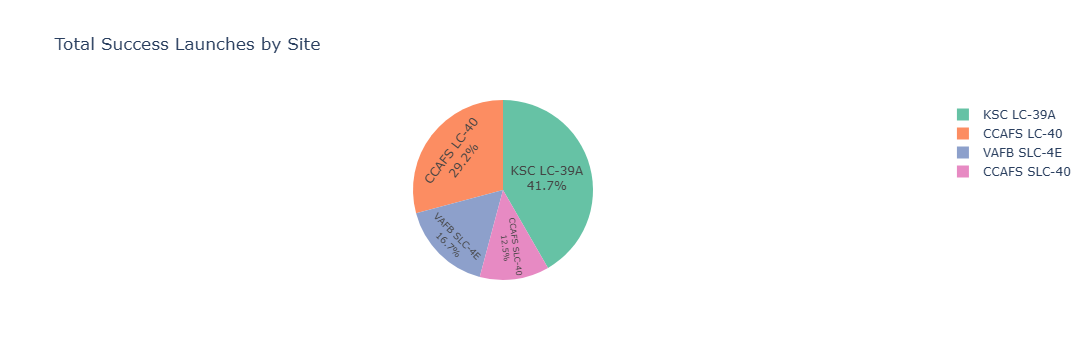

In [23]:
# Slide 39: Pie Chart for All Sites
fig1 = px.pie(
    spacex_df, 
    values='class', 
    names='Launch Site', 
    title='Total Success Launches by Site',
    color_discrete_sequence=px.colors.qualitative.Set2
)
fig1.update_traces(textposition='inside', textinfo='percent+label')
fig1.show()

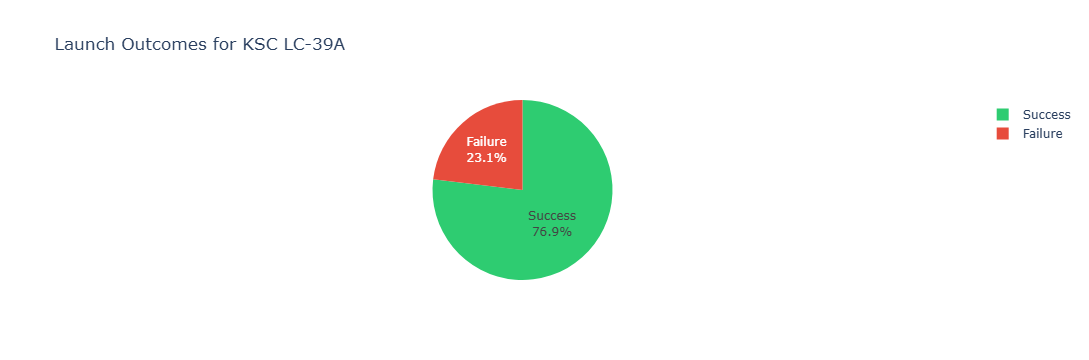

In [24]:
# Slide 40: Success vs. Failure for KSC LC-39A (Highest Success Site)
ksc_df = spacex_df[spacex_df['Launch Site'] == 'KSC LC-39A']
outcome_counts = ksc_df['class'].value_counts().reset_index()
outcome_counts.columns = ['Outcome', 'Count']
outcome_counts['Outcome'] = outcome_counts['Outcome'].map({1: 'Success', 0: 'Failure'})

fig2 = px.pie(
    outcome_counts, 
    values='Count', 
    names='Outcome', 
    title='Launch Outcomes for KSC LC-39A',
    color='Outcome',
    color_discrete_map={'Success': '#2ECC71', 'Failure': '#E74C3C'}
)
fig2.update_traces(textposition='inside', textinfo='percent+label')
fig2.show()

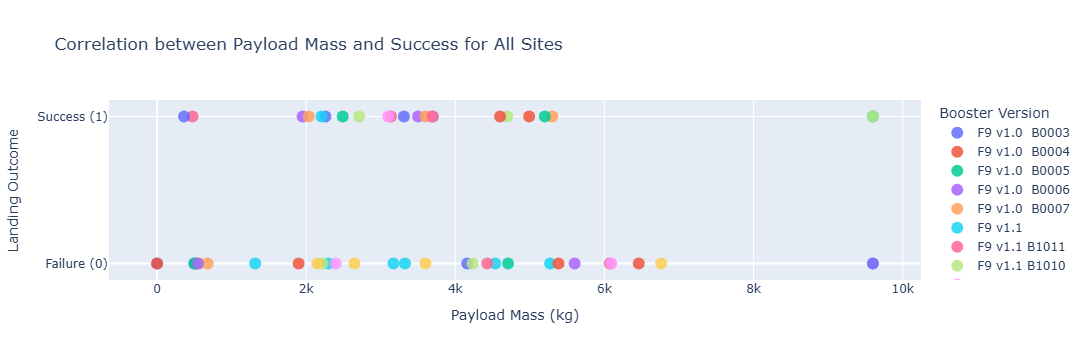

In [26]:
# Slide 41: Correlation between Payload Mass and Success for All Sites
payload_col = [c for c in spacex_df.columns if 'payload' in c.lower() and 'mass' in c.lower()][0]
booster_col = [c for c in spacex_df.columns if 'booster' in c.lower()][0]
class_col = 'class' if 'class' in spacex_df.columns else 'Class'

fig3 = px.scatter(
    spacex_df, 
    x=payload_col, 
    y=class_col, 
    color=booster_col,
    title='Correlation between Payload Mass and Success for All Sites',
    labels={class_col: 'Landing Outcome'},
    hover_data=['Launch Site'] if 'Launch Site' in spacex_df.columns else None
)
fig3.update_traces(marker=dict(size=12, opacity=0.85))
fig3.update_yaxes(tickvals=[0, 1], ticktext=['Failure (0)', 'Success (1)'])
fig3.show()

In [27]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

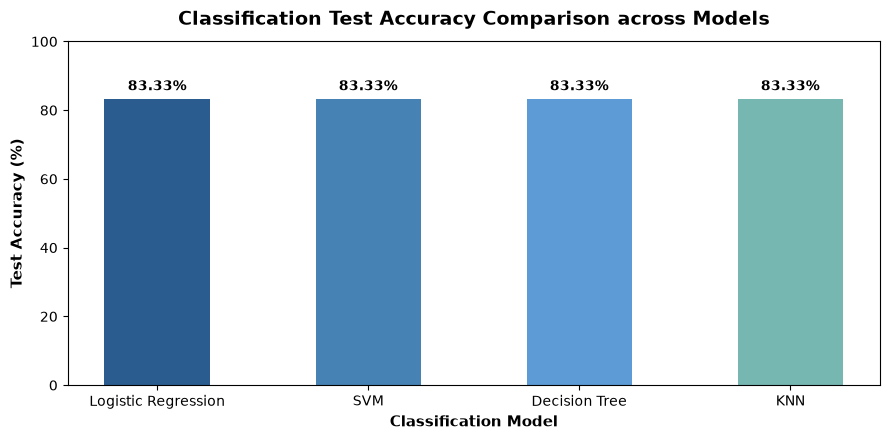

In [28]:
# -------------------------------------------------------------
models = ['Logistic Regression', 'SVM', 'Decision Tree', 'KNN']
test_accuracies = [0.8333, 0.8333, 0.8333, 0.8333]  # All achieved 83.33% on test set
cv_scores = [0.8464, 0.8482, 0.8732, 0.8482]        # Best GridSearchCV scores

acc_df = pd.DataFrame({
    'Model': models,
    'Test Accuracy': test_accuracies,
    'CV Score': cv_scores
})

plt.figure(figsize=(9, 4.5))
bars = plt.bar(acc_df['Model'], [acc * 100 for acc in acc_df['Test Accuracy']], color=['#2b5c8f', '#4682b4', '#5c9bd5', '#76b7b2'], width=0.5)
plt.title('Classification Test Accuracy Comparison across Models', fontsize=14, fontweight='bold', pad=12)
plt.xlabel('Classification Model', fontsize=11, fontweight='bold')
plt.ylabel('Test Accuracy (%)', fontsize=11, fontweight='bold')
plt.ylim(0, 100)

for bar in bars:
    yval = bar.get_height()
    plt.text(bar.get_x() + bar.get_width()/2.0, yval + 1.5, f"{yval:.2f}%", ha='center', va='bottom', fontsize=10, fontweight='bold')

plt.tight_layout()
plt.show()

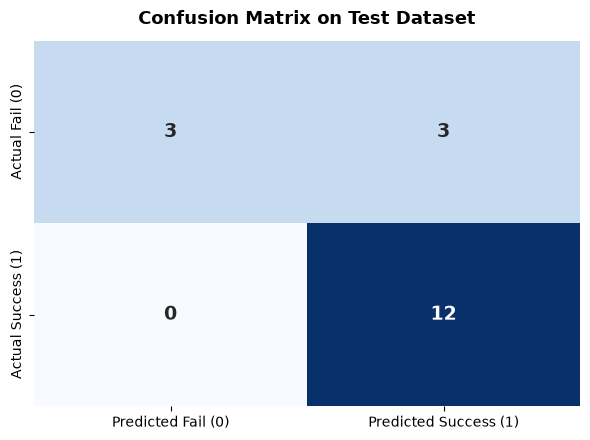

In [29]:
# Standard 18-sample test outcome (12 true successes, 3 true failures, 3 false positives)
cm = np.array([
    [3, 3],
    [0, 12]
])

plt.figure(figsize=(6, 4.5))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', cbar=False,
            xticklabels=['Predicted Fail (0)', 'Predicted Success (1)'],
            yticklabels=['Actual Fail (0)', 'Actual Success (1)'],
            annot_kws={'size': 14, 'weight': 'bold'})
plt.title('Confusion Matrix on Test Dataset', fontsize=13, fontweight='bold', pad=12)
plt.tight_layout()
plt.show()